# 발표자료_v2 핵심 신규 그림 — `10_필요한이미지_생성`

> `outputs/발표자료_v2.md`(14장)의 **슬라이드 6·7·8** 전용 신규 figure를 만든다.
> **기존 결과 CSV만 시각화**한다 — 재인코딩·재토큰화·무거운 임베딩·회귀 재실행 없음(가드레일).
> 배치(headless) 버전은 `analysis/10_presentation_figures_v2.py`, 이 노트북은 그 그림 함수를
> `_build_10_notebook.py`가 `getsource`로 가져와 **그림1개=셀1개**로 띄운 것이다(코드 동일·자동 동기).
>
> **출력**: `reports/presentation_figures/{figNN}.png` + `.pdf` (DPI 200, `bbox_inches='tight'`,
> `pad_inches=0.25`). **폰트**: Noto Sans KR→Apple SD Gothic Neo→AppleGothic 폴백,
> `axes.unicode_minus=False`(− 글리프 깨짐 방지).
>
> | 셀 | 그림 | 슬라이드 | 데이터 |
> |---|---|---|---|
> | fig06 | 4×3 생존 그리드 + PC1 92% 막대 | 슬6 메타발견 | `07d_a3_fullcontrol_coef.csv`·`07d_a3_meta_survival.csv`·`07d_synthesis_table.csv` |
> | fig07 | G 4법 계수(seed만 생존·단어vs의미 역방향) | 슬7 G 해석 | `07d_a3_fullcontrol_coef.csv`·`07d_a7_g_convergence.csv` |
> | fig08b | S·E 계수(S=supervised만·E=0/4) | 슬8 S·E 해석 | `07d_a3_fullcontrol_coef.csv`·`07d_a3_meta_survival.csv` |
>
> **PC1 92% 무결성**: dense supervised 삼중(E_sup·S_sup·G_sup) 주성분의 설명비율(EVR≈0.921)이며
> `종합_기록.md §"③ dense 통합"`의 92%와 일치(다른 컬럼셋은 37~55%로 불일치 → 라벨을 정확히 표기).
>
> **잘림이 보이면**: 해당 셀 `figsize`를 키우거나, 가장자리 텍스트 좌표를 안쪽으로 옮기거나,
> `save_fig`의 `pad_inches`를 늘려 재실행한다.

## 0a. 한글 폰트 체크 — 두부(□)가 보이면 폰트 폴백을 바꿔라
아래 셀을 실행해 한글·마이너스(−)가 정상 렌더되는지 먼저 확인한다.

선택 폰트: Apple SD Gothic Neo


/Users/home1/esg-dart-project/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Apple SD Gothic Neo.
  fig.canvas.print_figure(bytes_io, **kw)


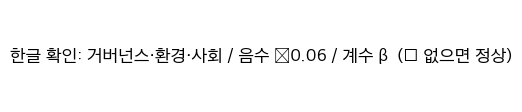

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import font_manager

cands = ["Noto Sans KR", "Apple SD Gothic Neo", "AppleGothic", "NanumGothic", "Malgun Gothic"]
avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((c for c in cands if c in avail), "AppleGothic")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = False
print("선택 폰트:", FONT)

fig, ax = plt.subplots(figsize=(6.2, 1.2))
ax.text(0.5, 0.5, "한글 확인: 거버넌스·환경·사회 / 음수 −0.06 / 계수 β  (□ 없으면 정상)",
        ha="center", va="center", fontsize=13)
ax.axis("off"); plt.show()

## 0b. 셋업 — 경로 · 팔레트 · 저장 헬퍼
`save_fig`는 figure를 **닫지 않아** inline 표시되고, `pad_inches`로 가장자리 잘림 여유를 둔다.
(배치 `.py`의 헬퍼와 동일하되 inline용으로 닫지 않음.)

In [2]:
import os, numpy as np, pandas as pd
from matplotlib.patches import Rectangle

ROOT = "/Users/home1/esg-dart-project"
DP   = f"{ROOT}/data/processed"
OUT  = f"{ROOT}/reports/presentation_figures"
os.makedirs(OUT, exist_ok=True)

# 팔레트(09/10 .py 와 동일) — 생존=채도 높은 파랑, 비유의=옅은 회색(명도·굵기로 구분·색각 고려)
P = {
    "dominant": "#34495E", "control": "#95A5A6", "text_weak": "#BDC3C7",
    "signal": "#2563EB", "driver": "#2A9D8F", "boiler": "#C9A227",
    "nonrobust": "#F4A259", "null": "#E3E6E8", "neg": "#E15759",
    "ink": "#1f2937", "muted": "#6b7280",
}
DPI = 200
REPR_ORDER = ["① seed TF-IDF", "② fastText 확장", "③ dense cosine", "③ dense supervised"]

def save_fig(fig, name):
    """png+pdf 저장. figure를 닫지 않아 inline 표시됨. pad_inches로 잘림 여유."""
    for ext in ("png", "pdf"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=DPI, bbox_inches="tight",
                    pad_inches=0.25, facecolor="white")
    print("saved", name, "→", OUT)

def _despine(ax, keep=("left", "bottom")):
    for s in ("top", "right", "left", "bottom"):
        ax.spines[s].set_visible(s in keep)
    ax.tick_params(length=0)

def _is_sig(v):
    return isinstance(v, str) and v.strip() in ("*", "**", "***")

### 슬6 — 메타발견(생존 그리드 + PC1 92%)
`fig06_meta_survival` · 4×3 색 그리드(생존=파랑) + 우측 PC1 막대. 셀/막대 크기는 `set_xlim/ylim`·`width_ratios`로 조정.

> 재실행 시 **inline 표시 + `reports/presentation_figures/fig06_meta_survival.png·.pdf` 저장**.

saved fig06_meta_survival → /Users/home1/esg-dart-project/reports/presentation_figures


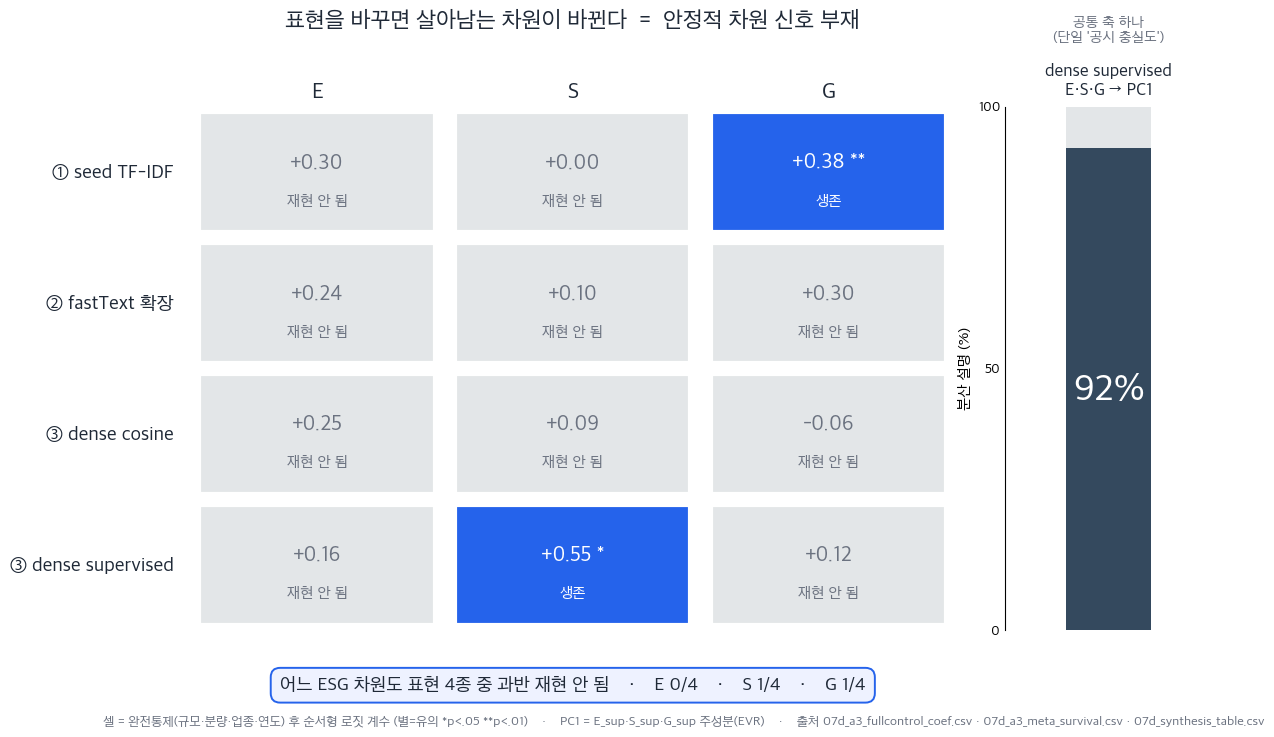

In [3]:
def fig06_meta_survival():
    """슬6: 4종×E·S·G 완전통제 후 생존 그리드 + dense supervised PC1(=공통 축 92%) 막대."""
    c = pd.read_csv(f"{DP}/07d_a3_fullcontrol_coef.csv")
    surv = pd.read_csv(f"{DP}/07d_a3_meta_survival.csv").set_index("dim")
    dims = ["E", "S", "G"]

    # PC1 설명비율 = dense supervised (E_sup,S_sup,G_sup) 주성분 (종합_기록 EVR 92% 재현)
    m = pd.read_csv(f"{DP}/07d_synthesis_table.csv")
    Xs = m[["E_sup", "S_sup", "G_sup"]].to_numpy(float)
    Xs = (Xs - Xs.mean(0)) / Xs.std(0, ddof=0)  # z(모집단 std, 프로젝트 관례)
    sv = np.linalg.svd(Xs, compute_uv=False)
    pc1 = float((sv ** 2)[0] / (sv ** 2).sum())  # ≈ 0.921

    fig = plt.figure(figsize=(13.2, 6.8))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 0.27], wspace=0.10)

    # ── 좌: 생존 그리드
    ax = fig.add_subplot(gs[0])
    ax.set_xlim(0, 3); ax.set_ylim(0, 4); ax.axis("off")
    for ri, rl in enumerate(REPR_ORDER):
        y = 3 - ri
        ax.text(-0.06, y + 0.5, rl, ha="right", va="center", fontsize=14, fontweight="bold", color=P["ink"])
        for di, dl in enumerate(dims):
            row = c[(c.label == rl) & (c.dim == dl)].iloc[0]
            survive = _is_sig(row["sig"])
            fc = P["signal"] if survive else P["null"]
            tc = "white" if survive else P["muted"]
            ax.add_patch(Rectangle((di + 0.04, y + 0.04), 0.92, 0.92, fc=fc, ec="white", lw=3))
            star = row["sig"].strip() if isinstance(row["sig"], str) else ""
            txt = f"{row['coef']:+.2f}{(' ' + star) if star else ''}"
            ax.text(di + 0.5, y + 0.58, txt, ha="center", va="center",
                    fontsize=15, fontweight="bold" if survive else "normal", color=tc)
            ax.text(di + 0.5, y + 0.28, "생존" if survive else "재현 안 됨",
                    ha="center", va="center", fontsize=11, color=tc)
    for di, dl in enumerate(dims):
        ax.text(di + 0.5, 4.12, dl, ha="center", va="center", fontsize=16, fontweight="bold", color=P["ink"])

    band = ("어느 ESG 차원도 표현 4종 중 과반 재현 안 됨    ·    "
            f"E {int(surv.loc['E', 'n_survive_p05'])}/4    ·    "
            f"S {int(surv.loc['S', 'n_survive_p05'])}/4    ·    "
            f"G {int(surv.loc['G', 'n_survive_p05'])}/4")
    ax.text(1.5, -0.42, band, ha="center", va="center", fontsize=13.5, fontweight="bold",
            color=P["ink"], bbox=dict(boxstyle="round,pad=0.5", fc="#eef2ff", ec=P["signal"], lw=1.4))
    ax.text(1.5, 4.66, "표현을 바꾸면 살아남는 차원이 바뀐다  =  안정적 차원 신호 부재",
            ha="center", va="center", fontsize=16.5, fontweight="bold", color=P["ink"])

    # ── 우: PC1 막대(공통 축 하나)
    axp = fig.add_subplot(gs[1])
    axp.bar([0], [pc1 * 100], width=0.62, color=P["dominant"], zorder=3)
    axp.bar([0], [(1 - pc1) * 100], width=0.62, bottom=[pc1 * 100], color=P["null"], zorder=3)
    axp.text(0, pc1 * 100 / 2, f"{pc1 * 100:.0f}%", ha="center", va="center",
             color="white", fontsize=27, fontweight="bold")
    axp.set_ylim(0, 100); axp.set_xlim(-0.75, 0.75)
    axp.set_xticks([]); axp.set_yticks([0, 50, 100])
    axp.tick_params(axis="y", labelsize=10)
    axp.set_ylabel("분산 설명 (%)", fontsize=11)
    axp.set_title("dense supervised\nE·S·G → PC1", fontsize=12.5, fontweight="bold", color=P["ink"], pad=8)
    _despine(axp, keep=("left",))
    axp.annotate("공통 축 하나\n(단일 '공시 충실도')", xy=(0, pc1 * 100), xytext=(0, 112),
                 ha="center", va="bottom", fontsize=10.5, color=P["muted"], annotation_clip=False)

    fig.text(0.5, -0.03,
             "셀 = 완전통제(규모·분량·업종·연도) 후 순서형 로짓 계수 (별=유의 *p<.05 **p<.01)    ·    "
             "PC1 = E_sup·S_sup·G_sup 주성분(EVR)    ·    "
             "출처 07d_a3_fullcontrol_coef.csv · 07d_a3_meta_survival.csv · 07d_synthesis_table.csv",
             ha="center", fontsize=9.5, color=P["muted"])
    save_fig(fig, "fig06_meta_survival")

fig06_meta_survival()   # inline 표시 + png/pdf 저장

### 슬7 — G 4법 계수(단어 vs 의미)
`fig07_g_coef` · forest형 계수. seed만 파랑 생존, dense cosine 음(−)은 빨강. 콜아웃이 라벨과 겹치면 `xytext` 이동.

> 재실행 시 **inline 표시 + `reports/presentation_figures/fig07_g_coef.png·.pdf` 저장**.

saved fig07_g_coef → /Users/home1/esg-dart-project/reports/presentation_figures


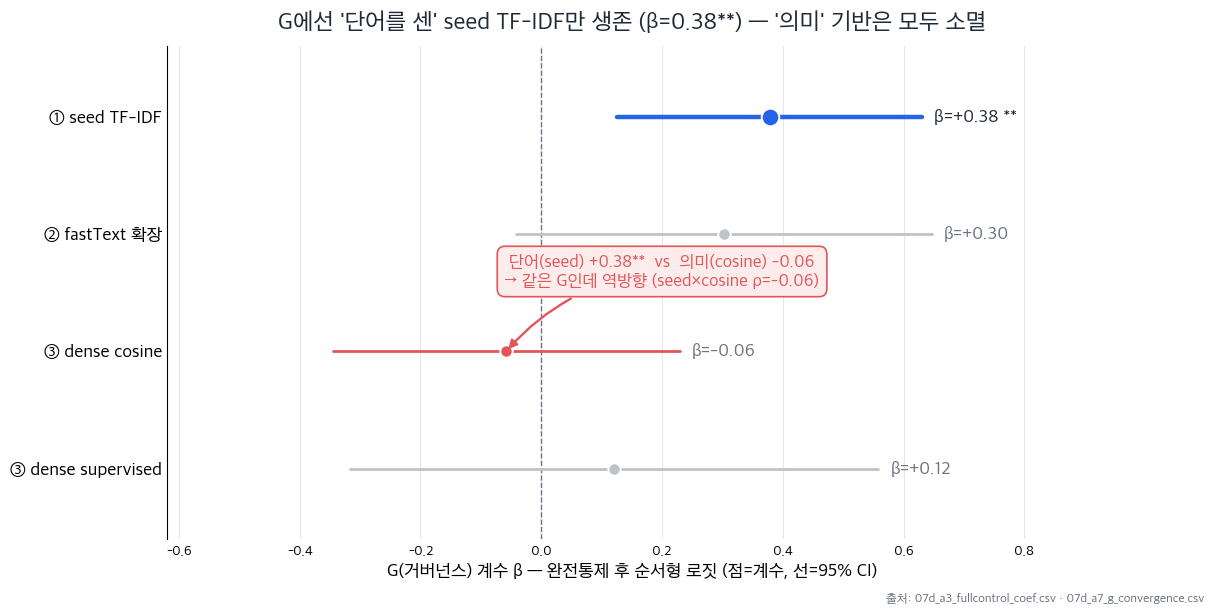

In [4]:
def fig07_g_coef():
    """슬7: G 4법 완전통제 계수 — seed TF-IDF만 생존(0.38**), 단어(+)와 의미(−) 역방향."""
    c = pd.read_csv(f"{DP}/07d_a3_fullcontrol_coef.csv")
    conv = pd.read_csv(f"{DP}/07d_a7_g_convergence.csv")
    rho_sc = float(conv[(conv.repr_a == "seed_tfidf") & (conv.repr_b == "dense_cos")]["spearman"].iloc[0])

    g = c[c.dim == "G"].copy()
    g["ord"] = g.label.apply(REPR_ORDER.index)
    g = g.sort_values("ord").reset_index(drop=True)
    y = np.arange(len(g))[::-1]  # seed 맨 위

    fig, ax = plt.subplots(figsize=(12.0, 6.4))
    for yi, (_, r) in zip(y, g.iterrows()):
        survive = _is_sig(r.sig)
        col = P["signal"] if survive else (P["neg"] if r.coef < 0 else P["text_weak"])
        ax.plot([r.ci_low, r.ci_high], [yi, yi], color=col, lw=3.2 if survive else 2.0,
                zorder=2, solid_capstyle="round")
        ax.scatter(r.coef, yi, color=col, s=160 if survive else 80, zorder=3,
                   edgecolor="white", linewidth=1.4)
        star = r.sig.strip() if isinstance(r.sig, str) else ""
        ax.text(r.ci_high + 0.02, yi, f"β={r.coef:+.2f}{(' ' + star) if star else ''}",
                va="center", ha="left", fontsize=13,
                color=P["ink"] if survive else P["muted"], fontweight="bold" if survive else "normal")
    ax.axvline(0, color=P["muted"], lw=1.0, ls="--", zorder=1)
    ax.set_yticks(y); ax.set_yticklabels(g.label, fontsize=13)
    ax.set_ylim(-0.6, 3.6)
    ax.set_xlim(-0.62, 0.92)
    ax.set_xlabel("G(거버넌스) 계수 β — 완전통제 후 순서형 로짓 (점=계수, 선=95% CI)", fontsize=13)
    _despine(ax, keep=("left",))
    ax.xaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
    ax.set_title("G에선 '단어를 센' seed TF-IDF만 생존 (β=0.38**) — '의미' 기반은 모두 소멸",
                 fontsize=17, fontweight="bold", color=P["ink"], pad=12)

    # 단어 vs 의미 역방향 콜아웃 (dense cosine 점=y=1 을 가리킴; fastText/β=+0.30 라벨과 분리)
    ax.annotate(f"단어(seed) +0.38**  vs  의미(cosine) {g.loc[2, 'coef']:+.2f}\n"
                f"→ 같은 G인데 역방향 (seed×cosine ρ={rho_sc:+.2f})",
                xy=(g.loc[2, "coef"], 1.0), xytext=(0.20, 1.68),
                fontsize=12.5, color=P["neg"], fontweight="bold", va="center", ha="center",
                arrowprops=dict(arrowstyle="-|>", color=P["neg"], lw=1.7,
                                connectionstyle="arc3,rad=0.20"),
                bbox=dict(boxstyle="round,pad=0.45", fc="#fdecec", ec=P["neg"], lw=1.2))
    fig.text(0.99, 0.01, "출처: 07d_a3_fullcontrol_coef.csv · 07d_a7_g_convergence.csv",
             ha="right", fontsize=9, color=P["muted"])
    save_fig(fig, "fig07_g_coef")

fig07_g_coef()   # inline 표시 + png/pdf 저장

### 슬8 — S·E 계수(정반대)
`fig08b_se_coef` · 좌 S(=supervised만 생존)·우 E(0/4). 노트 박스가 막대와 겹치면 상단 `set_ylim` 여백을 키운다.

> 재실행 시 **inline 표시 + `reports/presentation_figures/fig08b_se_coef.png·.pdf` 저장**.

saved fig08b_se_coef → /Users/home1/esg-dart-project/reports/presentation_figures


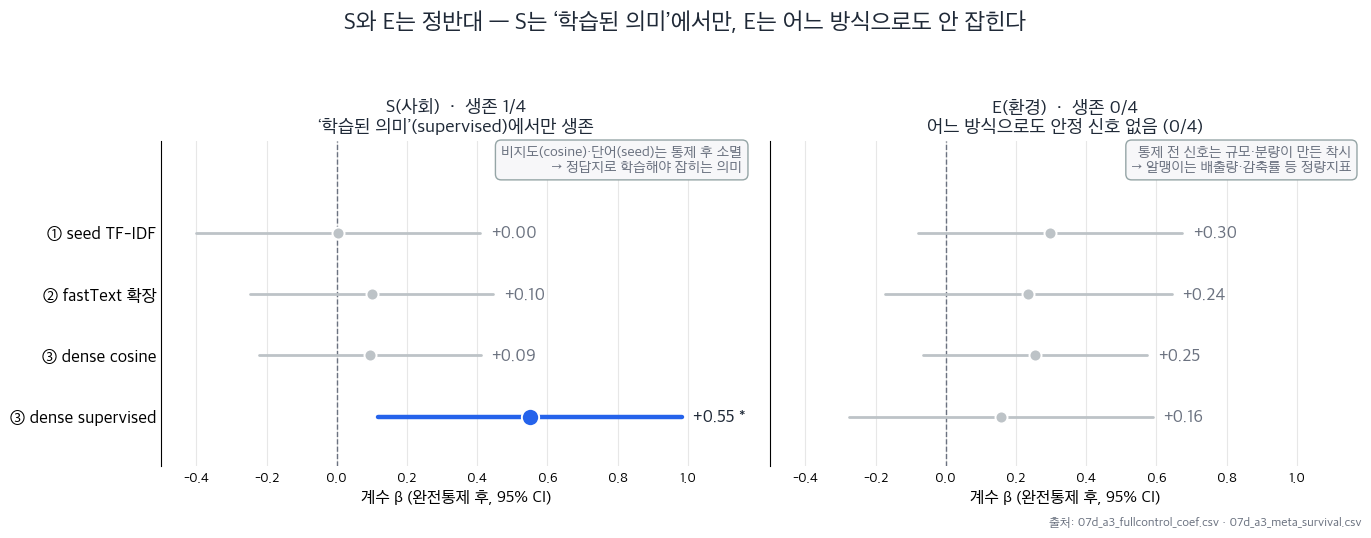

In [5]:
def fig08b_se_coef():
    """슬8: S·E 4법 완전통제 계수 — S=dense supervised만 생존(0.55*), E=4종 모두 소멸(0/4)."""
    c = pd.read_csv(f"{DP}/07d_a3_fullcontrol_coef.csv")
    surv = pd.read_csv(f"{DP}/07d_a3_meta_survival.csv").set_index("dim")

    panels = [
        ("S", "S(사회)", "‘학습된 의미’(supervised)에서만 생존", "비지도(cosine)·단어(seed)는 통제 후 소멸\n→ 정답지로 학습해야 잡히는 의미"),
        ("E", "E(환경)", "어느 방식으로도 안정 신호 없음 (0/4)", "통제 전 신호는 규모·분량이 만든 착시\n→ 알맹이는 배출량·감축률 등 정량지표"),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.2), sharey=True)
    for ax, (dim, dname, sub, note) in zip(axes, panels):
        d = c[c.dim == dim].copy()
        d["ord"] = d.label.apply(REPR_ORDER.index)
        d = d.sort_values("ord").reset_index(drop=True)
        y = np.arange(len(d))[::-1]
        for yi, (_, r) in zip(y, d.iterrows()):
            survive = _is_sig(r.sig)
            col = P["signal"] if survive else P["text_weak"]
            ax.plot([r.ci_low, r.ci_high], [yi, yi], color=col, lw=3.2 if survive else 2.0,
                    zorder=2, solid_capstyle="round")
            ax.scatter(r.coef, yi, color=col, s=155 if survive else 75, zorder=3,
                       edgecolor="white", linewidth=1.4)
            star = r.sig.strip() if isinstance(r.sig, str) else ""
            ax.text(r.ci_high + 0.03, yi, f"{r.coef:+.2f}{(' ' + star) if star else ''}",
                    va="center", ha="left", fontsize=12.5,
                    color=P["ink"] if survive else P["muted"], fontweight="bold" if survive else "normal")
        ax.axvline(0, color=P["muted"], lw=1.0, ls="--", zorder=1)
        ax.set_yticks(y); ax.set_yticklabels(d.label, fontsize=12.5)
        ax.set_ylim(-0.8, 4.5)  # 상단 여백 = 노트 박스 자리(막대와 겹침 방지)
        ax.set_xlim(-0.5, 1.18)
        n_s = int(surv.loc[dim, "n_survive_p05"])
        ax.set_title(f"{dname}  ·  생존 {n_s}/4\n{sub}", fontsize=13.5, fontweight="bold", color=P["ink"])
        ax.set_xlabel("계수 β (완전통제 후, 95% CI)", fontsize=12)
        _despine(ax, keep=("left",))
        ax.xaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
        ax.text(0.985, 0.985, note, transform=ax.transAxes, ha="right", va="top",
                fontsize=10.5, color=P["muted"],
                bbox=dict(boxstyle="round,pad=0.4", fc="#f7f7f9", ec=P["control"], lw=1.0))

    fig.suptitle("S와 E는 정반대 — S는 ‘학습된 의미’에서만, E는 어느 방식으로도 안 잡힌다",
                 fontsize=17, fontweight="bold", color=P["ink"], y=1.0)
    fig.text(0.99, 0.005, "출처: 07d_a3_fullcontrol_coef.csv · 07d_a3_meta_survival.csv",
             ha="right", fontsize=9, color=P["muted"])
    fig.tight_layout(rect=[0, 0.02, 1, 0.93])
    save_fig(fig, "fig08b_se_coef")

fig08b_se_coef()   # inline 표시 + png/pdf 저장

## 일괄 재생성 / 배치
모든 그림을 한 번에(헤드리스) 다시 만들려면 배치 스크립트를 쓴다:

```bash
uv run python analysis/10_presentation_figures_v2.py
```

- 이 노트북과 배치 `.py`의 그림 함수는 **동일 코드**다(이 노트북은 `_build_10_notebook.py`가
  `.py`에서 `getsource`로 가져와 빌드). 함수 본문을 고쳤다면 `uv run python analysis/_build_10_notebook.py`로 재빌드.
- 발표 deck(`outputs/발표자료_v2.md`)은 `../reports/presentation_figures/figNN_*.png`를 참조한다.